In [33]:
import pyarrow.parquet as pq
import pandas as pd
import matplotlib.pyplot as plt
import awkward as ak
import numpy as np
import plotly.graph_objects as go
import torch

In [31]:
import sys
from pathlib import Path

from src.data.event_jets_data_loading import EventJetsL1TriggerDataset

In [35]:
# Initialize test dataset
dataset = EventJetsL1TriggerDataset(
    parquet_dirs="/run/media/francesco/STORAGE/data_class/minbias",
    max_jets=14,
    features=["L1T_JetPuppiAK4_PT",
            "L1T_JetPuppiAK4_Eta",
            "L1T_JetPuppiAK4_Phi",
        ],
    preprocessing=False
)

# Initialize test dataloader
dataloader = torch.utils.data.DataLoader(
    dataset,
    batch_size=64,
    num_workers=0,
    pin_memory=True
)

In [36]:
pt = []
eta = []
phi = []
tot_events = 0
num_jets = []

for x, m in dataloader:
    pt.extend(x[:, :, 0][m])
    eta.extend(x[:, :, 1][m])
    phi.extend(x[:, :, 2][m])

    num_jets.extend(m.sum(axis=1))

    tot_events += x.shape[0]

In [37]:
print(f"Total events: {tot_events}")

Total events: 17565


In [38]:
# Initialize test dataset
dataset = EventJetsL1TriggerDataset(
    parquet_dirs="/run/media/francesco/STORAGE/data_class/ggHbb",
    max_jets=14,
    features=["L1T_JetPuppiAK4_PT",
            "L1T_JetPuppiAK4_Eta",
            "L1T_JetPuppiAK4_Phi",
        ],
    preprocessing=False
)

# Initialize test dataloader
dataloader = torch.utils.data.DataLoader(
    dataset,
    batch_size=64,
    num_workers=0,
    pin_memory=True
)

In [39]:
pt = []
eta = []
phi = []
tot_events = 0
num_jets = []

for x, m in dataloader:
    pt.extend(x[:, :, 0][m])
    eta.extend(x[:, :, 1][m])
    phi.extend(x[:, :, 2][m])

    num_jets.extend(m.sum(axis=1))

    tot_events += x.shape[0]

In [40]:
print(f"Total events: {tot_events}")

Total events: 19483


Using device: cuda

================ METRICS ================
Accuracy    : 0.9061
Precision   : 0.9427
Recall      : 0.8745
Specificity : 0.9411
F1-score    : 0.9073
ROC-AUC     : 0.9623
PR-AUC      : 0.9714

Confusion matrix components:
TN = 3306
FP = 207
FN = 489
TP = 3408

Classification report:
              precision    recall  f1-score   support

     Minbias     0.8711    0.9411    0.9048      3513
       ggHbb     0.9427    0.8745    0.9073      3897

    accuracy                         0.9061      7410
   macro avg     0.9069    0.9078    0.9061      7410
weighted avg     0.9088    0.9061    0.9061      7410

Number of test events: 7410

Confusion matrix:
[[3306  207]
 [ 489 3408]]


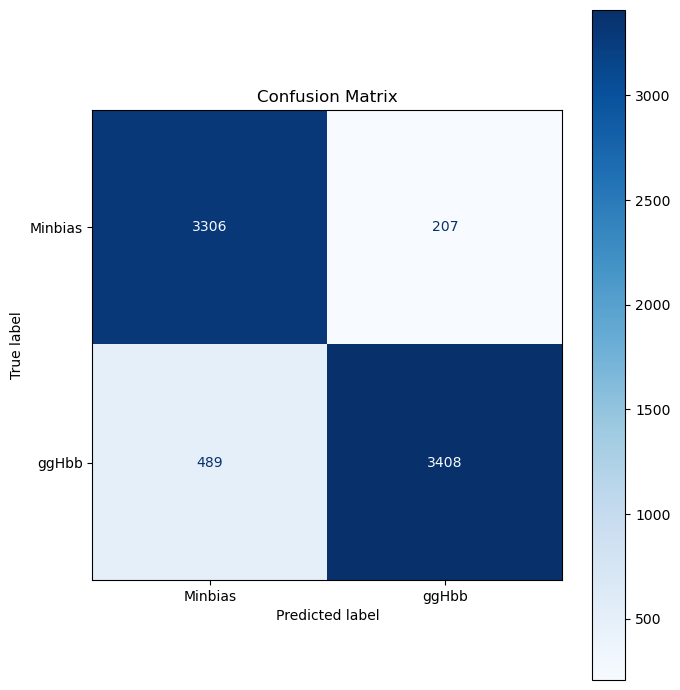


Normalized confusion matrix:
[[0.941076   0.058924  ]
 [0.12548114 0.87451886]]


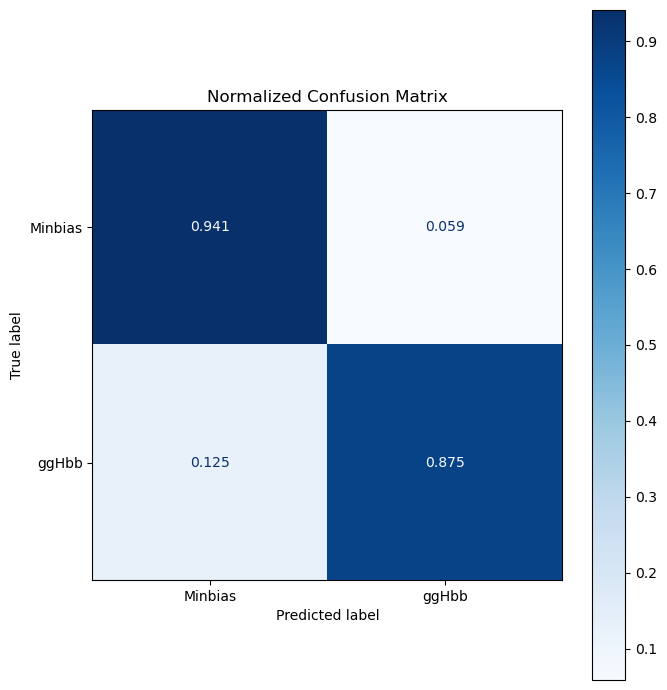


Done.


In [19]:
import os

import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import lightning as L

from classifier.dataset import TokenDataModule
from classifier.classifier_model import EncoderClassificationModule 


# Checkpoint
CHECKPOINT_PATH = "checkpoints_classifier/class/v20-epoch=09-train_acc=0.9287-class.ckpt"

# Processes
CLASS_NAMES = [
    "Minbias",
    "ggHbb",
]

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Using device: {device}")


# ============================================================
# DATA MODULE
# ============================================================

data_module = TokenDataModule(
    tokens_path = "classifier/tokens/tokens.pt",
    masks_path = "classifier/tokens/masks.pt",
    labels_path = "classifier/tokens/labels.pt",
    cb_size = 1024,
    batch_size = 32,
    num_workers =0,
    test_size = 0.20,
    seed = 15
)

data_module.setup(stage="test")

test_loader = data_module.test_dataloader()


# ============================================================
# LOAD MODEL FROM CHECKPOINT
# ============================================================

model = EncoderClassificationModule.load_from_checkpoint(
    CHECKPOINT_PATH
)

model = model.to(device)
model.eval()


# ============================================================
# INFERENCE
# ============================================================

all_labels = []
all_predictions = []
all_probabilities = []


with torch.no_grad():

    for batch_idx, batch in enumerate(test_loader):

        x = batch['tokens']
        mask = batch['mask']
        labels = batch['label']

        x = x.to(device)
        mask = mask.to(device)
        labels = labels.to(device)

        # ----------------------------------------------------
        # Forward
        # ----------------------------------------------------

        logits = model(x, mask)

        # ----------------------------------------------------
        # Binary classification
        # ----------------------------------------------------

        if logits.ndim == 1:
            probabilities = torch.sigmoid(logits)
            predictions = (probabilities >= 0.5).long()

        elif logits.shape[-1] == 1:
            probabilities = torch.sigmoid(logits.squeeze(-1))
            predictions = (probabilities >= 0.5).long()

        # ----------------------------------------------------
        # Multi-class classification
        # ----------------------------------------------------

        else:
            probabilities = torch.softmax(logits, dim=-1)
            predictions = torch.argmax(probabilities, dim=-1)

        all_labels.append(labels.detach().cpu())
        all_predictions.append(predictions.detach().cpu())
        all_probabilities.append(probabilities.detach().cpu())


# ============================================================
# CONCATENATE
# ============================================================

y_true = torch.cat(all_labels).numpy()
y_pred = torch.cat(all_predictions).numpy()

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
)

# ============================================================
# CLASSIFICATION METRICS
# ============================================================

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0,
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0,
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0,
)

# ============================================================
# CONFUSION MATRIX COMPONENTS
# ============================================================

tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

# ============================================================
# ROC-AUC AND PR-AUC
# ============================================================

# For binary classification, use the probability of class 1
y_prob = torch.cat(all_probabilities).numpy()

if y_prob.ndim > 1:
    y_prob = y_prob[:, 1]

roc_auc = roc_auc_score(
    y_true,
    y_prob,
)

pr_auc = average_precision_score(
    y_true,
    y_prob,
)

# ============================================================
# PRINT METRICS
# ============================================================

print("\n================ METRICS ================")

print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1-score    : {f1:.4f}")
print(f"ROC-AUC     : {roc_auc:.4f}")
print(f"PR-AUC      : {pr_auc:.4f}")

print("\nConfusion matrix components:")
print(f"TN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    )
)

print(f"Number of test events: {len(y_true)}")


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
)

print("\nConfusion matrix:")
print(cm)


# ============================================================
# RAW CONFUSION MATRIX
# ============================================================

fig, ax = plt.subplots(figsize=(7, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES,
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True,
)

ax.set_title("Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")

plt.tight_layout()
plt.show()


# ============================================================
# NORMALIZED CONFUSION MATRIX
# ============================================================

cm_normalized = confusion_matrix(
    y_true,
    y_pred,
    normalize="true",
)

print("\nNormalized confusion matrix:")
print(cm_normalized)


fig, ax = plt.subplots(figsize=(7, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=CLASS_NAMES,
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=".3f",
    colorbar=True,
)

ax.set_title("Normalized Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")

plt.tight_layout()
plt.show()

print("\nDone.")

/tmp/ipykernel_8810/979666503.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


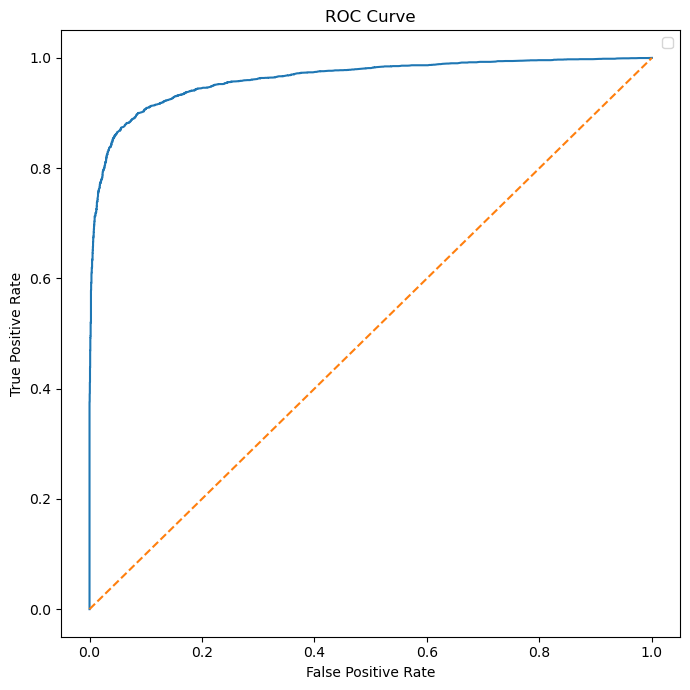

/tmp/ipykernel_8810/979666503.py:60: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


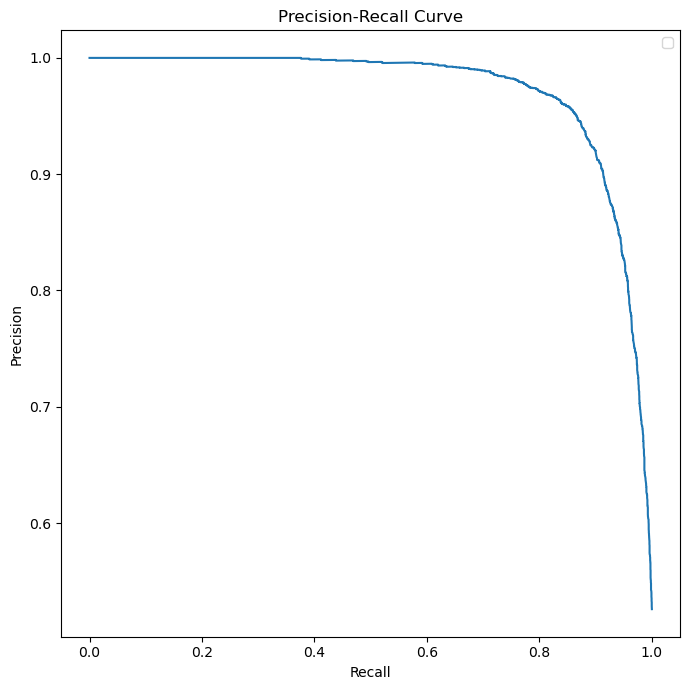

In [14]:
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc,
)

# ============================================================
# ROC CURVE
# ============================================================

fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc_curve = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(
    fpr,
    tpr,
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve")
ax.legend()

plt.tight_layout()
plt.show()


# ============================================================
# PRECISION-RECALL CURVE
# ============================================================

precision_curve, recall_curve, _ = precision_recall_curve(
    y_true,
    y_prob,
)

pr_auc_curve = auc(
    recall_curve,
    precision_curve,
)

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(
    recall_curve,
    precision_curve,
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve")
ax.legend()

plt.tight_layout()
plt.show()

In [10]:
acc_runs = np.array([0.9085, 0.9018, 0.9061])
prec_runs = np.array([0.9538, 0.9518, 0.9427])
recall_runs = np.array([0.8681, 0.8566, 0.8745])
spec_runs = np.array([0.9533, 0.9519, 0.9411])
f1_runs = np.array([0.9089, 0.9017, 0.9073])
roc_runs = np.array([0.9625, 0.9621, 0.9623])
pr_runs = np.array([0.9712, 0.9703, 0.9714])

In [11]:
l = [acc_runs, prec_runs, recall_runs, spec_runs, f1_runs, roc_runs, pr_runs]

for metric in l:
    print(np.mean(metric))
    print(np.std(metric))
    print("------")
    

0.9054666666666668
0.002771682200798292
------
0.9494333333333334
0.004830688931773143
------
0.8664
0.007405853540724848
------
0.9487666666666668
0.00545119762580255
------
0.9059666666666667
0.0030868898407440974
------
0.9622999999999999
0.00016329931618557254
------
0.9709666666666666
0.00047842333648022493
------


# Baseline


Using device: cuda

================ METRICS ================
Accuracy    : 0.9231
Precision   : 0.9291
Recall      : 0.9243
Specificity : 0.9217
F1-score    : 0.9267
ROC-AUC     : 0.9735
PR-AUC      : 0.9806

Confusion matrix components:
TN = 3238
FP = 275
FN = 295
TP = 3602

Classification report:
              precision    recall  f1-score   support

     Minbias     0.9165    0.9217    0.9191      3513
       ggHbb     0.9291    0.9243    0.9267      3897

    accuracy                         0.9231      7410
   macro avg     0.9228    0.9230    0.9229      7410
weighted avg     0.9231    0.9231    0.9231      7410

Number of test events: 7410

Confusion matrix:
[[3238  275]
 [ 295 3602]]


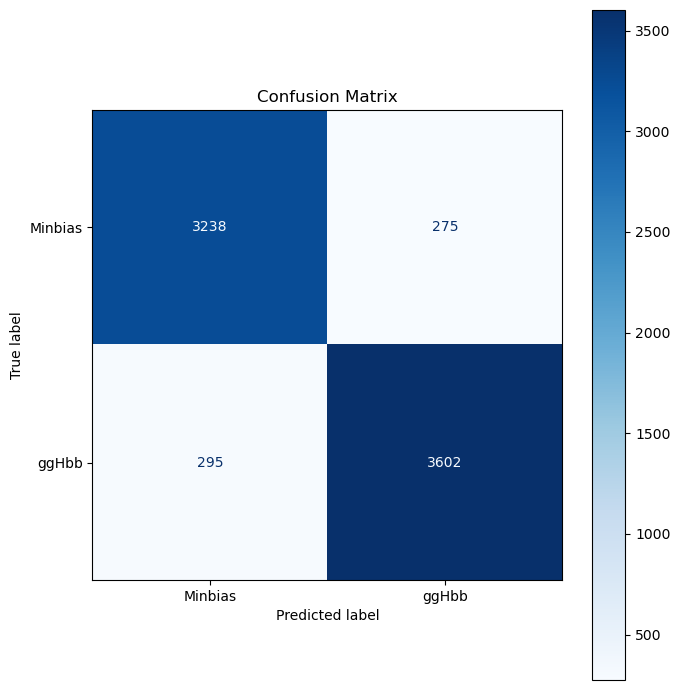


Normalized confusion matrix:
[[0.92171933 0.07828067]
 [0.07569926 0.92430074]]


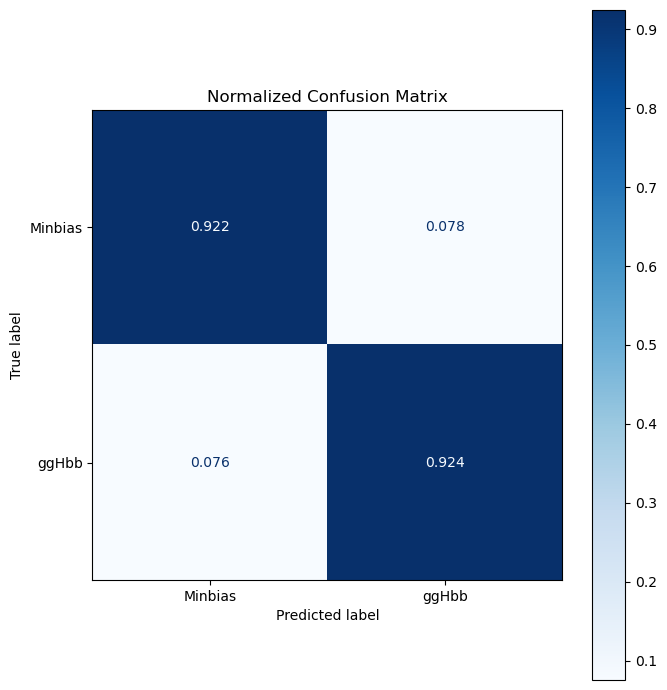


Done.


In [20]:
import os

import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import lightning as L

from classifier_baseline.dataset_base import OriginalDataModule
from classifier_baseline.model_baseline import EncoderClassificationModule 


# Checkpoint
CHECKPOINT_PATH = "checkpoints_base_classifier/base_class/v21-epoch=09-train_acc=0.9211-base_class.ckpt"

# Processes
CLASS_NAMES = [
    "Minbias",
    "ggHbb",
]

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Using device: {device}")


# ============================================================
# DATA MODULE
# ============================================================

data_module = OriginalDataModule(
    data_path = "classifier_baseline/data/data.pt",
    masks_path = "classifier_baseline/data/masks.pt",
    labels_path = "classifier_baseline/data/labels.pt",
    batch_size = 32,
    num_workers =0,
    test_size = 0.20,
    seed = 15
)

data_module.setup(stage="test")

test_loader = data_module.test_dataloader()


# ============================================================
# LOAD MODEL FROM CHECKPOINT
# ============================================================

model = EncoderClassificationModule.load_from_checkpoint(
    CHECKPOINT_PATH
)

model = model.to(device)
model.eval()


# ============================================================
# INFERENCE
# ============================================================

all_labels = []
all_predictions = []
all_probabilities = []


with torch.no_grad():

    for batch_idx, batch in enumerate(test_loader):

        x = batch['data']
        mask = batch['mask']
        labels = batch['label']

        x = x.to(device)
        mask = mask.to(device)
        labels = labels.to(device)

        # ----------------------------------------------------
        # Forward
        # ----------------------------------------------------

        logits = model(x, mask)

        # ----------------------------------------------------
        # Binary classification
        # ----------------------------------------------------

        if logits.ndim == 1:
            probabilities = torch.sigmoid(logits)
            predictions = (probabilities >= 0.5).long()

        elif logits.shape[-1] == 1:
            probabilities = torch.sigmoid(logits.squeeze(-1))
            predictions = (probabilities >= 0.5).long()

        # ----------------------------------------------------
        # Multi-class classification
        # ----------------------------------------------------

        else:
            probabilities = torch.softmax(logits, dim=-1)
            predictions = torch.argmax(probabilities, dim=-1)

        all_labels.append(labels.detach().cpu())
        all_predictions.append(predictions.detach().cpu())
        all_probabilities.append(probabilities.detach().cpu())


# ============================================================
# CONCATENATE
# ============================================================

y_true_base = torch.cat(all_labels).numpy()
y_pred_base = torch.cat(all_predictions).numpy()

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
)

# ============================================================
# CLASSIFICATION METRICS
# ============================================================

accuracy = accuracy_score(y_true_base, y_pred_base)

precision = precision_score(
    y_true_base,
    y_pred_base,
    zero_division=0,
)

recall = recall_score(
    y_true_base,
    y_pred_base,
    zero_division=0,
)

f1 = f1_score(
    y_true_base,
    y_pred_base,
    zero_division=0,
)

# ============================================================
# CONFUSION MATRIX COMPONENTS
# ============================================================

tn, fp, fn, tp = confusion_matrix(y_true_base, y_pred_base).ravel()

specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

# ============================================================
# ROC-AUC AND PR-AUC
# ============================================================

# For binary classification, use the probability of class 1
y_prob_base = torch.cat(all_probabilities).numpy()

if y_prob_base.ndim > 1:
    y_prob_base = y_prob_base[:, 1]

roc_auc = roc_auc_score(
    y_true_base,
    y_prob_base,
)

pr_auc = average_precision_score(
    y_true_base,
    y_prob_base,
)

# ============================================================
# PRINT METRICS
# ============================================================

print("\n================ METRICS ================")

print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1-score    : {f1:.4f}")
print(f"ROC-AUC     : {roc_auc:.4f}")
print(f"PR-AUC      : {pr_auc:.4f}")

print("\nConfusion matrix components:")
print(f"TN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\nClassification report:")
print(
    classification_report(
        y_true_base,
        y_pred_base,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    )
)

print(f"Number of test events: {len(y_true_base)}")


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true_base,
    y_pred_base,
)

print("\nConfusion matrix:")
print(cm)


# ============================================================
# RAW CONFUSION MATRIX
# ============================================================

fig, ax = plt.subplots(figsize=(7, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES,
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True,
)

ax.set_title("Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")

plt.tight_layout()
plt.show()


# ============================================================
# NORMALIZED CONFUSION MATRIX
# ============================================================

cm_normalized = confusion_matrix(
    y_true_base,
    y_pred_base,
    normalize="true",
)

print("\nNormalized confusion matrix:")
print(cm_normalized)


fig, ax = plt.subplots(figsize=(7, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=CLASS_NAMES,
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=".3f",
    colorbar=True,
)

ax.set_title("Normalized Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")

plt.tight_layout()
plt.show()

print("\nDone.")

/tmp/ipykernel_43058/979666503.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


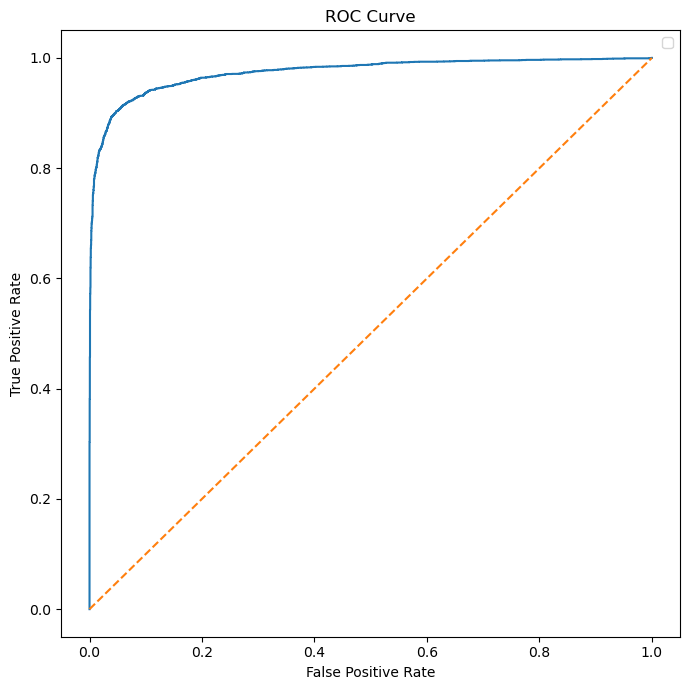

/tmp/ipykernel_43058/979666503.py:60: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


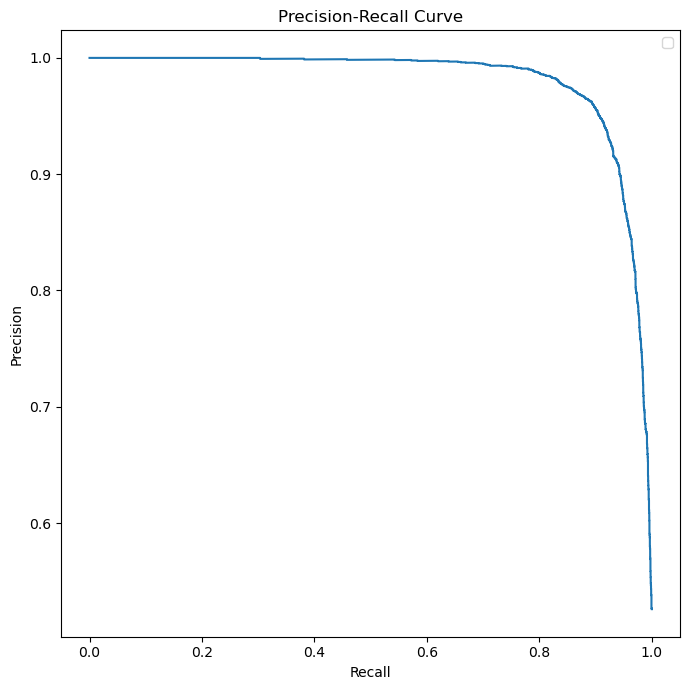

In [4]:
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc,
)

# ============================================================
# ROC CURVE
# ============================================================

fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc_curve = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(
    fpr,
    tpr,
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve")
ax.legend()

plt.tight_layout()
plt.show()


# ============================================================
# PRECISION-RECALL CURVE
# ============================================================

precision_curve, recall_curve, _ = precision_recall_curve(
    y_true,
    y_prob,
)

pr_auc_curve = auc(
    recall_curve,
    precision_curve,
)

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(
    recall_curve,
    precision_curve,
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve")
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
acc_runs = np.array([0.9248, 0.9243, 0.9231])
prec_runs = np.array([0.9434, 0.9585, 0.9291])
recall_runs = np.array([0.9117, 0.8948, 0.9243])
spec_runs = np.array([0.9394, 0.9570, 0.9217])
f1_runs = np.array([0.9273, 0.9255, 0.9267])
roc_runs = np.array([0.9726, 0.9721, 0.9735])
pr_runs = np.array([0.9791, 0.9789, 0.9806])


In [7]:
l = [acc_runs, prec_runs, recall_runs, spec_runs, f1_runs, roc_runs, pr_runs]

for metric in l:
    print(np.mean(metric))
    print(np.std(metric))
    print("------")
    

0.9240666666666666
0.0007133644853010615
------
0.9436666666666667
0.012003980821192417
------
0.9102666666666667
0.012085896279916046
------
0.9393666666666666
0.014411183928540438
------
0.9265
0.0007483314773547949
------
0.9727333333333333
0.0005792715732327845
------
0.9795333333333334
0.0007586537784494233
------


# Reconstruction

Using device: cuda

================ METRICS ================
Accuracy    : 0.9178
Precision   : 0.9288
Recall      : 0.9138
Specificity : 0.9223
F1-score    : 0.9212
ROC-AUC     : 0.9705
PR-AUC      : 0.9782

Confusion matrix components:
TN = 3240
FP = 273
FN = 336
TP = 3561

Classification report:
              precision    recall  f1-score   support

     Minbias     0.9060    0.9223    0.9141      3513
       ggHbb     0.9288    0.9138    0.9212      3897

    accuracy                         0.9178      7410
   macro avg     0.9174    0.9180    0.9177      7410
weighted avg     0.9180    0.9178    0.9178      7410

Number of test events: 7410

Confusion matrix:
[[3240  273]
 [ 336 3561]]


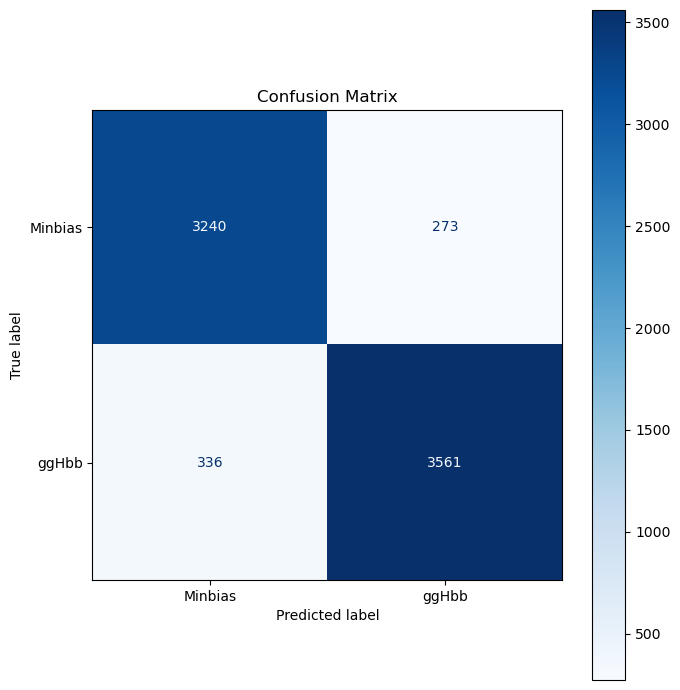


Normalized confusion matrix:
[[0.92228864 0.07771136]
 [0.08622017 0.91377983]]


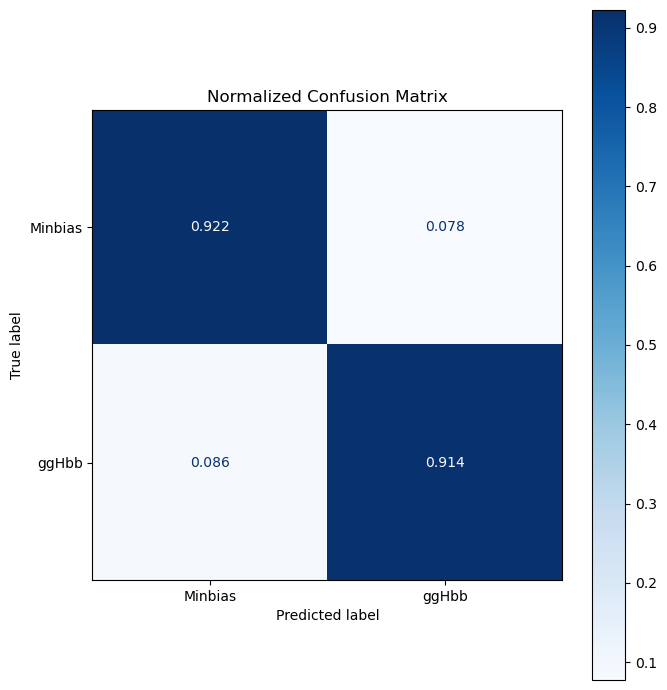


Done.


In [21]:
import os

import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import lightning as L

from classifier_recon.dataset_recon import ReconDataModule
from classifier_recon.model_recon import EncoderClassificationModule 


# Checkpoint
CHECKPOINT_PATH = "checkpoints_reco_classifier/reco_class/v6-epoch=09-train_acc=0.9149-reco_class.ckpt"

# Processes
CLASS_NAMES = [
    "Minbias",
    "ggHbb",
]

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Using device: {device}")


# ============================================================
# DATA MODULE
# ============================================================

data_module = ReconDataModule(
    data_path = "classifier_recon/data_reco/data_reco.pt",
    masks_path = "classifier_recon/data_reco/masks.pt",
    labels_path = "classifier_recon/data_reco/labels.pt",
    batch_size = 32,
    num_workers =0,
    test_size = 0.20,
    seed = 15
)

data_module.setup(stage="test")

test_loader = data_module.test_dataloader()


# ============================================================
# LOAD MODEL FROM CHECKPOINT
# ============================================================

model = EncoderClassificationModule.load_from_checkpoint(
    CHECKPOINT_PATH
)

model = model.to(device)
model.eval()


# ============================================================
# INFERENCE
# ============================================================

all_labels = []
all_predictions = []
all_probabilities = []


with torch.no_grad():

    for batch_idx, batch in enumerate(test_loader):

        x = batch['data_reco']
        mask = batch['mask']
        labels = batch['label']

        x = x.to(device)
        mask = mask.to(device)
        labels = labels.to(device)

        # ----------------------------------------------------
        # Forward
        # ----------------------------------------------------

        logits = model(x, mask)

        # ----------------------------------------------------
        # Binary classification
        # ----------------------------------------------------

        if logits.ndim == 1:
            probabilities = torch.sigmoid(logits)
            predictions = (probabilities >= 0.5).long()

        elif logits.shape[-1] == 1:
            probabilities = torch.sigmoid(logits.squeeze(-1))
            predictions = (probabilities >= 0.5).long()

        # ----------------------------------------------------
        # Multi-class classification
        # ----------------------------------------------------

        else:
            probabilities = torch.softmax(logits, dim=-1)
            predictions = torch.argmax(probabilities, dim=-1)

        all_labels.append(labels.detach().cpu())
        all_predictions.append(predictions.detach().cpu())
        all_probabilities.append(probabilities.detach().cpu())


# ============================================================
# CONCATENATE
# ============================================================

y_true_recon = torch.cat(all_labels).numpy()
y_pred_recon = torch.cat(all_predictions).numpy()

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
)

# ============================================================
# CLASSIFICATION METRICS
# ============================================================

accuracy = accuracy_score(y_true_recon, y_pred_recon)

precision = precision_score(
    y_true_recon,
    y_pred_recon,
    zero_division=0,
)

recall = recall_score(
    y_true_recon,
    y_pred_recon,
    zero_division=0,
)

f1 = f1_score(
    y_true_recon,
    y_pred_recon,
    zero_division=0,
)

# ============================================================
# CONFUSION MATRIX COMPONENTS
# ============================================================

tn, fp, fn, tp = confusion_matrix(y_true_recon, y_pred_recon).ravel()

specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

# ============================================================
# ROC-AUC AND PR-AUC
# ============================================================

# For binary classification, use the probability of class 1
y_prob_recon = torch.cat(all_probabilities).numpy()

if y_prob_recon.ndim > 1:
    y_prob_recon = y_prob_recon[:, 1]

roc_auc = roc_auc_score(
    y_true_recon,
    y_prob_recon,
)

pr_auc = average_precision_score(
    y_true_recon,
    y_prob_recon,
)

# ============================================================
# PRINT METRICS
# ============================================================

print("\n================ METRICS ================")

print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1-score    : {f1:.4f}")
print(f"ROC-AUC     : {roc_auc:.4f}")
print(f"PR-AUC      : {pr_auc:.4f}")

print("\nConfusion matrix components:")
print(f"TN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\nClassification report:")
print(
    classification_report(
        y_true_recon,
        y_pred_recon,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0,
    )
)

print(f"Number of test events: {len(y_true_recon)}")


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true_recon,
    y_pred_recon,
)

print("\nConfusion matrix:")
print(cm)


# ============================================================
# RAW CONFUSION MATRIX
# ============================================================

fig, ax = plt.subplots(figsize=(7, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES,
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True,
)

ax.set_title("Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")

plt.tight_layout()
plt.show()


# ============================================================
# NORMALIZED CONFUSION MATRIX
# ============================================================

cm_normalized = confusion_matrix(
    y_true_recon,
    y_pred_recon,
    normalize="true",
)

print("\nNormalized confusion matrix:")
print(cm_normalized)


fig, ax = plt.subplots(figsize=(7, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=CLASS_NAMES,
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=".3f",
    colorbar=True,
)

ax.set_title("Normalized Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")

plt.tight_layout()
plt.show()

print("\nDone.")

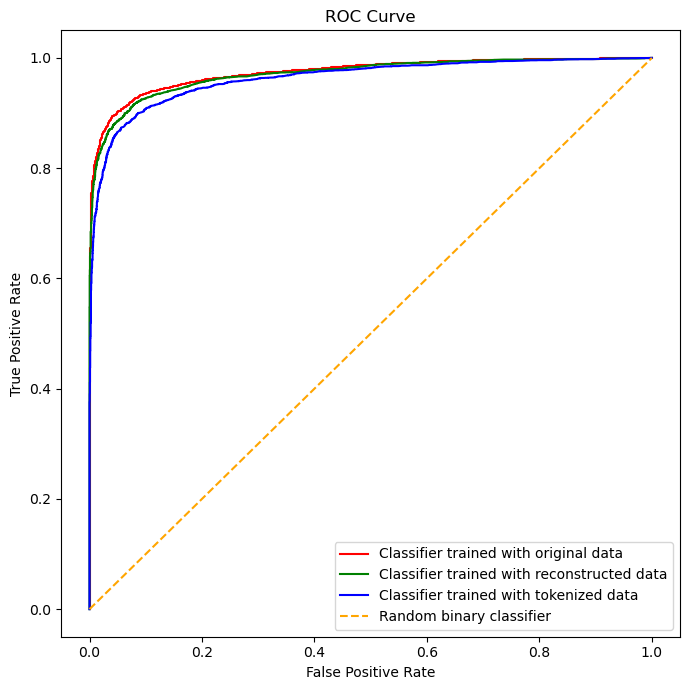

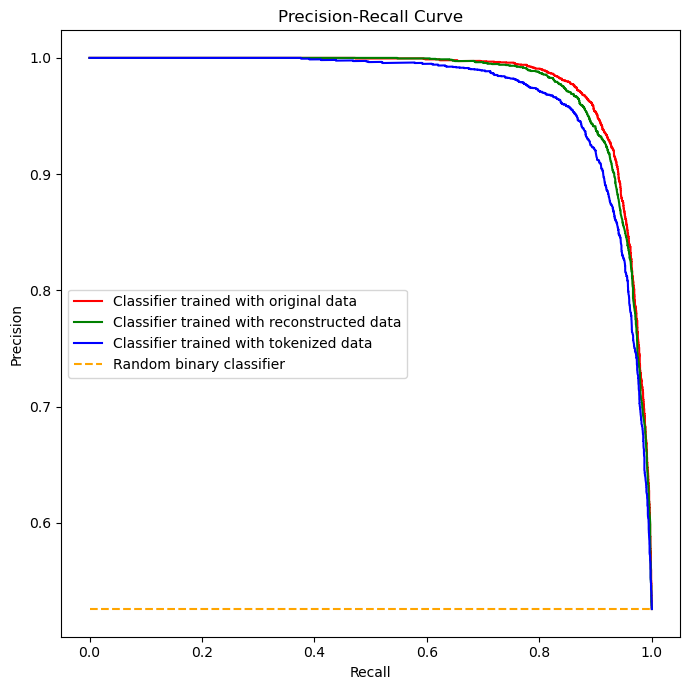

In [58]:
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc,
)

# ============================================================
# ROC CURVE
# ============================================================

fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc_curve = auc(fpr, tpr)

fpr_base, tpr_base, _ = roc_curve(y_true_base, y_prob_base)
roc_auc_curve_base = auc(fpr_base, tpr_base)

fpr_recon, tpr_recon, _ = roc_curve(y_true_recon, y_prob_recon)
roc_auc_curve_recon = auc(fpr_recon, tpr_recon)

fig, ax = plt.subplots(figsize=(7, 7))



ax.plot(
    fpr_base,
    tpr_base,
    color="red",
    label="Classifier trained with original data"
)

ax.plot(
    fpr_recon,
    tpr_recon,
    color="green",
    label="Classifier trained with reconstructed data"
)

ax.plot(
    fpr,
    tpr,
    color="blue",
    label="Classifier trained with tokenized data"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="orange",
    label="Random binary classifier"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve")
ax.legend()

plt.tight_layout()
plt.show()


# ============================================================
# PRECISION-RECALL CURVE
# ============================================================

precision_curve, recall_curve, _ = precision_recall_curve(
    y_true,
    y_prob,
)

precision_curve_base, recall_curve_base, _ = precision_recall_curve(
    y_true_base,
    y_prob_base,
)

precision_curve_recon, recall_curve_recon, _ = precision_recall_curve(
    y_true_recon,
    y_prob_recon,
)

pr_auc_curve = auc(
    recall_curve,
    precision_curve,
)


fig, ax = plt.subplots(figsize=(7, 7))



ax.plot(
    recall_curve_base,
    precision_curve_base,
    color="red",
    label="Classifier trained with original data"
)
ax.plot(
    recall_curve_recon,
    precision_curve_recon,
    color="green",
    label="Classifier trained with reconstructed data"
)

ax.plot(
    recall_curve,
    precision_curve,
    color="blue",
    label="Classifier trained with tokenized data"
)

ax.plot(
    [0, 1],
    [0.5258, 0.5258],
    linestyle="--",
    color="orange",
    label="Random binary classifier"
)


ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve")
ax.legend()

plt.tight_layout()
plt.show()

In [56]:
recall_curve_base

array([1.00000000e+00, 1.00000000e+00, 1.00000000e+00, ...,
       7.69822941e-04, 2.56607647e-04, 0.00000000e+00], shape=(7342,))

In [5]:
acc_runs = np.array([0.9186, 0.9157, 0.9178])
prec_runs = np.array([0.9294, 0.9384, 0.9288])
recall_runs = np.array([0.9148, 0.8986, 0.9138])
spec_runs = np.array([0.9229, 0.9345, 0.9223])
f1_runs = np.array([0.9220, 0.9181, 0.9212])
roc_runs = np.array([0.9693, 0.9689, 0.9705])
pr_runs = np.array([0.9761, 0.9762, 0.9782])

In [6]:
l = [acc_runs, prec_runs, recall_runs, spec_runs, f1_runs, roc_runs, pr_runs]

for metric in l:
    print(np.mean(metric))
    print(np.std(metric))
    print("------")
    

0.9173666666666666
0.0012229290885229461
------
0.9321999999999999
0.004390899680020046
------
0.9090666666666666
0.007412302086546538
------
0.9265666666666666
0.005615059117132136
------
0.9204333333333334
0.0016819301082057186
------
0.9695666666666667
0.0006798692684790501
------
0.9768333333333333
0.000967241208569792
------
